# Dropout: How Randomly Switching Off Units Reduces Overfitting

A network with enough capacity can **memorize** a small training set, including its mistakes: training loss goes to zero while performance on new data stalls or gets worse. **Dropout** (Srivastava et al., 2014) is a very cheap regularizer against this: during training, every hidden unit is **zeroed independently with probability `p`** on every forward pass, and the survivors are scaled up by `1/(1-p)`.

```
 training, every step a fresh random mask:        inference: all units on, no mask

   x --> [Linear] --> [ReLU] --> [Dropout p] --> ...          x --> [Linear] --> [ReLU] --> ...
                          h = (h1 h2 h3 h4 h5)
                          m = ( 1  0  1  1  0 )      (m_i = 0 with probability p)
                          out = h * m / (1 - p)
```

Two common stories explain why this helps. **(1) No co-adaptation:** a unit cannot rely on specific other units being present, so it has to learn features that are useful on their own. **(2) Implicit ensemble:** every mask defines a different thinned sub-network, and the full network used at test time approximates the average of exponentially many of them.

**What you will do**

1. Implement dropout from scratch and verify its statistics against `nn.Dropout`
2. Train the **same network with and without dropout** on a small dataset in which **20% of the training labels are corrupted** (so that memorization is visible and costly), and compare learning curves and test performance (5 seeds)
3. Sweep the dropout rate `p` to see the under-/over-regularization trade-off
4. Test the two explanations: **robustness to losing units**, and **averaging over many masks**
5. Look at **calibration**: dropout's effect on over-confidence
6. Find out **when dropout helps less**: vary the amount of label noise and the amount of training data

Everything runs on CPU in a few minutes.

## 0. Setup

In [1]:
import copy
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

SEED = 0


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
torch.set_num_threads(1)          # tiny networks run fastest single-threaded on CPU
print("torch", torch.__version__)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# scikit-learn digits: 8x8 handwritten digit images, 10 classes.
# Fixed validation (300) and test (500) sets with CLEAN labels; the rest is a pool from which we draw small training sets.
digits = load_digits()
Xd = (digits.data / 16.0).astype(np.float32)
yd = digits.target.astype(np.int64)
X_pool, X_rest, y_pool, y_rest = train_test_split(Xd, yd, test_size=800, stratify=yd, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_rest, y_rest, train_size=300, stratify=y_rest, random_state=SEED)
Xva_t, yva_t, Xte_t, yte_t = map(torch.tensor, (X_va, y_va, X_te, y_te))
Xpool_t, ypool_t = torch.tensor(X_pool), torch.tensor(y_pool)


def make_train(n, noise, seed=0):
    """First n pool images, with a fraction `noise` of their labels replaced by a random WRONG class.
    Validation and test labels are always clean."""
    X, y_true = Xpool_t[:n], ypool_t[:n]
    y, corrupted = y_true.clone(), torch.zeros(n, dtype=torch.bool)
    if noise > 0:
        rng = np.random.default_rng(seed)
        idx = rng.choice(n, int(round(noise * n)), replace=False)
        y[idx] = torch.tensor((y_true[idx].numpy() + rng.integers(1, 10, len(idx))) % 10)
        corrupted[idx] = True
    return X, y, y_true, corrupted


N_TRAIN, NOISE = 200, 0.2                        # main experiments: 200 training images, 20% corrupted labels
Xtr_t, ytr_t, ytrue_t, CORR = make_train(N_TRAIN, NOISE)
print(f"pool={len(X_pool)}  train(main)={N_TRAIN}  val={len(X_va)}  test={len(X_te)}")
print(f"corrupted training labels: {int(CORR.sum())} of {N_TRAIN} ({CORR.float().mean():.0%});  "
      f"a network that ignored the noise entirely could reach at most {1 - CORR.float().mean():.0%} accuracy on the given labels")

torch 2.15.0+cu132
pool=997  train(main)=200  val=300  test=500
corrupted training labels: 40 of 200 (20%);  a network that ignored the noise entirely could reach at most 80% accuracy on the given labels


## 1. Dropout from scratch

**Inverted dropout.** In training, draw a mask `m` with `m_i ~ Bernoulli(1 - p)` and output `h * m / (1 - p)`. The division by `1 - p` is what makes the layer **unbiased**: `E[out] = h * (1 - p) / (1 - p) = h`. Because the expectation is already right, **inference needs no change at all** (dropout is simply switched off). Older formulations scaled the weights at test time instead; both are equivalent.

The price is noise: each unit's output now has variance `h^2 * p / (1 - p)`, which grows quickly as `p` approaches 1.

In [2]:
class ScratchDropout(nn.Module):
    def __init__(self, p=0.5):
        super().__init__()
        self.p = p

    def forward(self, x):
        if not self.training or self.p == 0.0:
            return x                                       # inference: identity
        mask = (torch.rand_like(x) >= self.p).float()      # keep each unit with probability 1 - p
        return x * mask / (1.0 - self.p)                   # rescale so the expectation is unchanged


# Verify the statistics against nn.Dropout on a constant input h = 1 (so any variation comes from the mask)
set_seed()
h = torch.ones(200_000)
print(f"{'p':>5} | {'zeroed frac':>11} {'(theory)':>9} | {'mean out':>9} {'(theory)':>9} | {'var out':>8} {'(theory p/(1-p))':>17} | {'mean, nn.Dropout':>17}")
for p in (0.1, 0.3, 0.5, 0.8):
    out = ScratchDropout(p).train()(h)
    ref = nn.Dropout(p).train()(h)
    print(f"{p:>5} | {(out == 0).float().mean():>11.3f} {p:>9.3f} | {out.mean():>9.3f} {1.0:>9.3f} | {out.var():>8.3f} {p / (1 - p):>17.3f} | {ref.mean():>17.3f}")

print("\neval mode is the identity:", torch.equal(ScratchDropout(0.5).eval()(h), h))
print("without the 1/(1-p) rescale the mean output would be", round((h * (torch.rand_like(h) >= 0.5)).mean().item(), 3), "instead of 1.0 (p = 0.5)")

    p | zeroed frac  (theory) |  mean out  (theory) |  var out  (theory p/(1-p)) |  mean, nn.Dropout
  0.1 |       0.100     0.100 |     1.000     1.000 |    0.111             0.111 |             1.000
  0.3 |       0.300     0.300 |     1.000     1.000 |    0.429             0.429 |             1.000
  0.5 |       0.501     0.500 |     0.999     1.000 |    1.000             1.000 |             1.001
  0.8 |       0.799     0.800 |     1.006     1.000 |    4.018             4.000 |             1.004

eval mode is the identity: True
without the 1/(1-p) rescale the mean output would be 0.5 instead of 1.0 (p = 0.5)


**What to notice.** The measured fraction of zeroed units, the mean and the variance match theory to about three decimals, and they match `nn.Dropout`. The mean stays at 1.0 thanks to the `1/(1-p)` rescale (without it the mean would drop to 0.5 at `p = 0.5`), `eval()` mode is the exact identity, and the noise variance `p/(1-p)` is 1.0 at `p = 0.5` but already 4.0 at `p = 0.8`: high dropout rates inject a lot of noise.

### 1a. What the masks look like

Eight consecutive training-mode forward passes through a 32-unit layer: each row is one pass, and a filled cell is a unit that was kept (`p = 0.5`). The network is effectively a different thinned sub-network at every step.

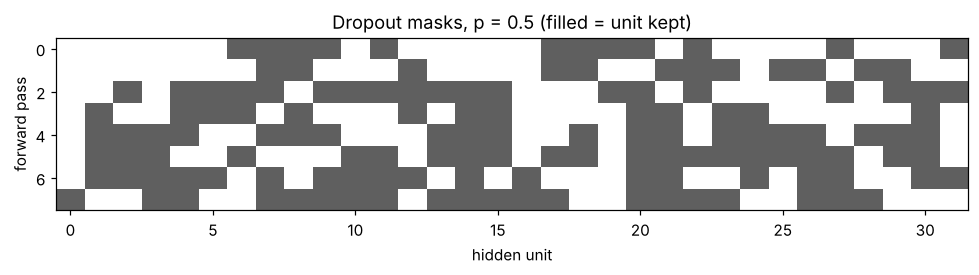

In [3]:
set_seed(3)
masks = (torch.rand(8, 32) >= 0.5).numpy()
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.imshow(masks, cmap="gray_r", vmin=0, vmax=1.6, aspect="auto"); ax.grid(False)
ax.set_xlabel("hidden unit"); ax.set_ylabel("forward pass")
ax.set_title("Dropout masks, p = 0.5 (filled = unit kept)")
plt.tight_layout(); plt.show()

## 2. The network, the training loop and the metrics

A deliberately over-parameterized MLP: **3 hidden layers of 256 ReLU units** (about 150 thousand parameters) for only 200 training images, 40 of which carry a wrong label. We use Adam (`lr = 1e-3`) with **no weight decay and no early stopping**, for 150 epochs, so that nothing but dropout stands between the network and memorization. Dropout is applied after each hidden activation.

Besides the usual losses and accuracies, we track the **memorization rate**: among the 40 corrupted training examples, the fraction for which the network predicts the *wrong label it was given*. A network that learned the real pattern should disagree with those labels; a network that memorized should agree with them.

All training curves report the loss in `eval()` mode (dropout off), so that train and validation are measured the same way.

In [4]:
class MLP(nn.Module):
    def __init__(self, p=0.0, width=256, depth=3, in_dim=64, out_dim=10):
        super().__init__()
        self.p = p
        layers, d = [], in_dim
        for _ in range(depth):
            layers += [nn.Linear(d, width), nn.ReLU(), nn.Dropout(p)]
            d = width
        self.body = nn.Sequential(*layers)
        self.head = nn.Linear(width, out_dim)

    def forward(self, x, ablate=0.0):
        """ablate: probability of zeroing each hidden unit at *test* time WITHOUT rescaling (damage test, section 5a)."""
        if ablate == 0.0:
            return self.head(self.body(x))
        for layer in self.body:
            x = layer(x)
            if isinstance(layer, nn.ReLU):
                x = x * (torch.rand_like(x) >= ablate).float()
        return self.head(x)


def new_model(p, seed=0, **kw):
    set_seed(seed)
    return MLP(p, **kw)


@torch.no_grad()
def logits_of(model, X, train_mode=False):
    model.train(train_mode)
    out = model(X)
    model.eval()
    return out


def nll_acc(logits, y):
    return F.cross_entropy(logits, y).item(), (logits.argmax(1) == y).float().mean().item()


def fit(model, X, y, epochs=150, lr=1e-3, batch_size=32, seed=0, corrupted=None):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed)
    h = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc", "memorized")}
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(len(X), generator=g)
        for i in range(0, len(X), batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            F.cross_entropy(model(X[idx]), y[idx]).backward(); opt.step()
        lt = logits_of(model, X)
        tl, ta = nll_acc(lt, y)
        vl, va = nll_acc(logits_of(model, Xva_t), yva_t)
        mem = (lt[corrupted].argmax(1) == y[corrupted]).float().mean().item() if corrupted is not None and corrupted.any() else float("nan")
        for k, v in zip(h, (tl, ta, vl, va, mem)):
            h[k].append(v)
    return h


print(new_model(0.5))
print("parameters:", sum(p.numel() for p in new_model(0.5).parameters()))

MLP(
  (body): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.5, inplace=False)
    (6): Linear(in_features=256, out_features=256, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.5, inplace=False)
  )
  (head): Linear(in_features=256, out_features=10, bias=True)
)
parameters: 150794


## 3. With and without dropout

Same architecture, same (noisy) data, same initialization and batch order: the only difference is `p = 0` against `p = 0.5`. Validation and test labels are clean. We run **5 seeds** of each. The cell trains all ten networks and keeps them for the later sections.

trained 10 networks in 24s


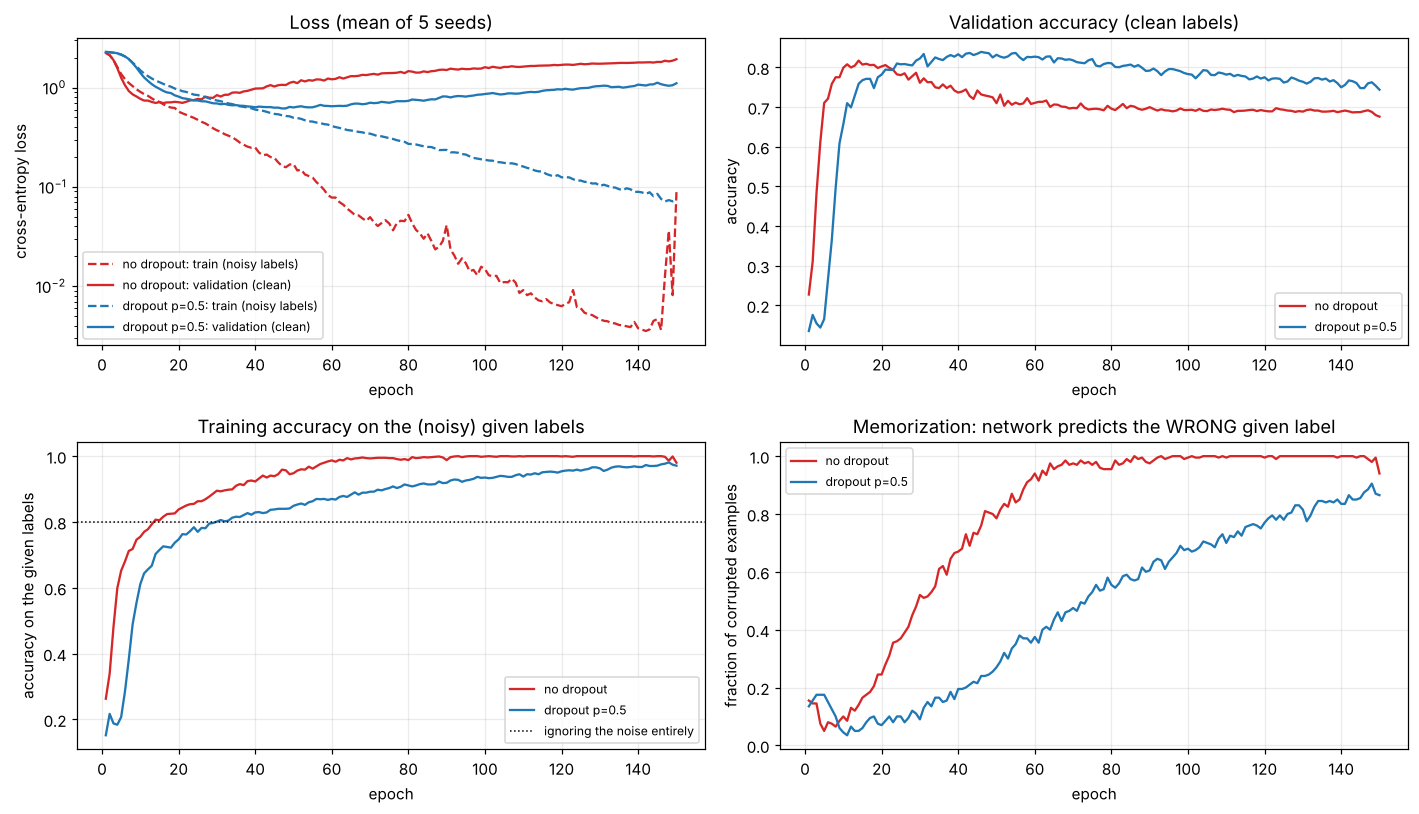

In [5]:
SEEDS = range(5)
EPOCHS = 150
runs = {}                                           # (p, seed) -> (model, history)


def run(p, seed, epochs=EPOCHS):
    m = new_model(p, seed=seed)
    return m, fit(m, Xtr_t, ytr_t, epochs=epochs, seed=seed, corrupted=CORR)


t0 = time.time()
for p in (0.0, 0.5):
    for s in SEEDS:
        runs[(p, s)] = run(p, s)
print(f"trained 10 networks in {time.time() - t0:.0f}s")

fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
styles = {0.0: ("C3", "no dropout"), 0.5: ("C0", "dropout p=0.5")}
ep = np.arange(1, EPOCHS + 1)
for p, (c, lab) in styles.items():
    hist = [runs[(p, s)][1] for s in SEEDS]
    mean = lambda k: np.mean([h[k] for h in hist], 0)
    axes[0, 0].plot(ep, mean("train_loss"), color=c, ls="--", label=f"{lab}: train (noisy labels)")
    axes[0, 0].plot(ep, mean("val_loss"), color=c, label=f"{lab}: validation (clean)")
    axes[0, 1].plot(ep, mean("val_acc"), color=c, label=lab)
    axes[1, 0].plot(ep, mean("train_acc"), color=c, label=lab)
    axes[1, 1].plot(ep, mean("memorized"), color=c, label=lab)
axes[0, 0].set_yscale("log"); axes[0, 0].set_ylabel("cross-entropy loss"); axes[0, 0].set_title("Loss (mean of 5 seeds)")
axes[0, 1].set_ylabel("accuracy"); axes[0, 1].set_title("Validation accuracy (clean labels)")
axes[1, 0].axhline(1 - CORR.float().mean(), color="k", ls=":", lw=1, label="ignoring the noise entirely")
axes[1, 0].set_ylabel("accuracy on the given labels"); axes[1, 0].set_title("Training accuracy on the (noisy) given labels")
axes[1, 1].set_ylabel("fraction of corrupted examples"); axes[1, 1].set_title("Memorization: network predicts the WRONG given label")
for ax in axes.flat:
    ax.set_xlabel("epoch"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What to notice.**

- **Both networks overfit, and the validation curves show it.** The no-dropout network drives its training loss to about 0.003 while its validation loss bottoms out near 0.67 around epoch 17 and then climbs to about 1.9. Validation accuracy peaks at 0.82 (epoch 14) and decays to 0.68 as the network starts fitting the corrupted labels. The dotted line in the bottom-left panel marks 80%: a network that had learned the real pattern and ignored the noise would sit there, and anything above it means the corrupted labels are being fitted.
- **Dropout slows memorization down.** The bottom-right panel is the cleanest view: the plain network reproduces 94% of the corrupted labels by epoch 60 and 100% by epoch 100, whereas the dropout network is at 38% at epoch 60, 68% at epoch 100, and 86% at epoch 150. Its validation loss bottoms out later and lower (about 0.60 around epoch 50), peak validation accuracy is higher (0.84 at epoch 46), and the decay afterwards is slower, so at the end of training it is well ahead.
- **Dropout does not prevent memorization here, it delays and softens it.** Given enough epochs the dropout network also fits most of the corrupted labels. It also learns more slowly at the start (the blue curves lag for the first 10 epochs), which is the usual price of the noise.
- The sudden jump in the no-dropout training loss at the very end is a single seed (seed 2) that had a loss spike in its last epochs, an instability of the unregularized run that we left in.

### 3a. Final numbers on the held-out test set

The test set was never used for anything. We report the **final epoch** (no early stopping and no picking the best epoch), mean and standard deviation over the 5 seeds. 'memorized' is the fraction of the 40 corrupted training examples whose wrong label the network reproduces. For reference we also show the best validation loss over all epochs and when it occurred.

In [6]:
def summarize(p):
    rows = []
    for s in SEEDS:
        m, h = runs[(p, s)]
        lt = logits_of(m, Xtr_t)
        ta = (lt.argmax(1) == ytr_t).float().mean().item()
        mem = (lt[CORR].argmax(1) == ytr_t[CORR]).float().mean().item()
        el, ea = nll_acc(logits_of(m, Xte_t), yte_t)
        rows.append((ta, mem, ea, el, min(h["val_loss"]), int(np.argmin(h["val_loss"])) + 1))
    return np.array(rows)


print(f"{'':<14} {'train acc':>9} {'memorized':>10} {'test acc':>14} {'test loss':>14} {'best val loss':>14} {'at epoch':>9}")
summ = {}
for p, (c, lab) in styles.items():
    summ[p] = summarize(p)
    mu, sd = summ[p].mean(0), summ[p].std(0)
    print(f"{lab:<14} {mu[0]:>9.3f} {mu[1]:>10.3f} {mu[2]:>8.3f}+-{sd[2]:.3f} {mu[3]:>8.3f}+-{sd[3]:.3f} {mu[4]:>14.3f} {mu[5]:>9.0f}")
print("\nper-seed test accuracy  no dropout:", summ[0.0][:, 2].round(3), " dropout:", summ[0.5][:, 2].round(3))
print("seeds where dropout has the higher test accuracy:", int((summ[0.5][:, 2] > summ[0.0][:, 2]).sum()), "of 5")

               train acc  memorized       test acc      test loss  best val loss  at epoch
no dropout         0.980      0.940    0.705+-0.034    1.716+-0.303          0.670        17
dropout p=0.5      0.971      0.865    0.767+-0.013    0.929+-0.040          0.603        50

per-seed test accuracy  no dropout: [0.73  0.728 0.64  0.706 0.722]  dropout: [0.78  0.754 0.774 0.748 0.778]
seeds where dropout has the higher test accuracy: 5 of 5


**What to notice.** At the final epoch dropout gives **higher test accuracy (0.767 against 0.705) and roughly half the test loss (0.93 against 1.72)**, with a much smaller spread across seeds on the loss (0.04 against 0.30). It wins in all 5 seeds. The memorization rate is lower too (0.87 against 0.94), and the 0.94 for the plain network is itself pulled down by the spiked seed: the other four reach 1.00 and their test accuracy is 0.72 on average, so excluding that seed the gap is about 4 points rather than 6, with dropout still ahead.

Two caveats the numbers make plain. **First, this comparison has no early stopping.** If we had stopped each network at its best validation epoch, the gap would be far smaller: the best validation loss is 0.67 without dropout against 0.60 with it. Dropout makes the *end-of-training* model much better; it does not conjure a much better *best-ever* model, and in practice the two techniques are complementary. **Second, we deliberately made overfitting costly** by corrupting 20% of the training labels. Section 6 shows how much that matters.

## 4. How much dropout? The regularization trade-off

`p = 0` means no regularization; `p` close to 1 destroys so much of the signal that the network **underfits**. In between there should be a sweet spot. We sweep `p` from 0 to 0.9 (5 seeds each) and plot final train and test performance.

sweep done in 47s


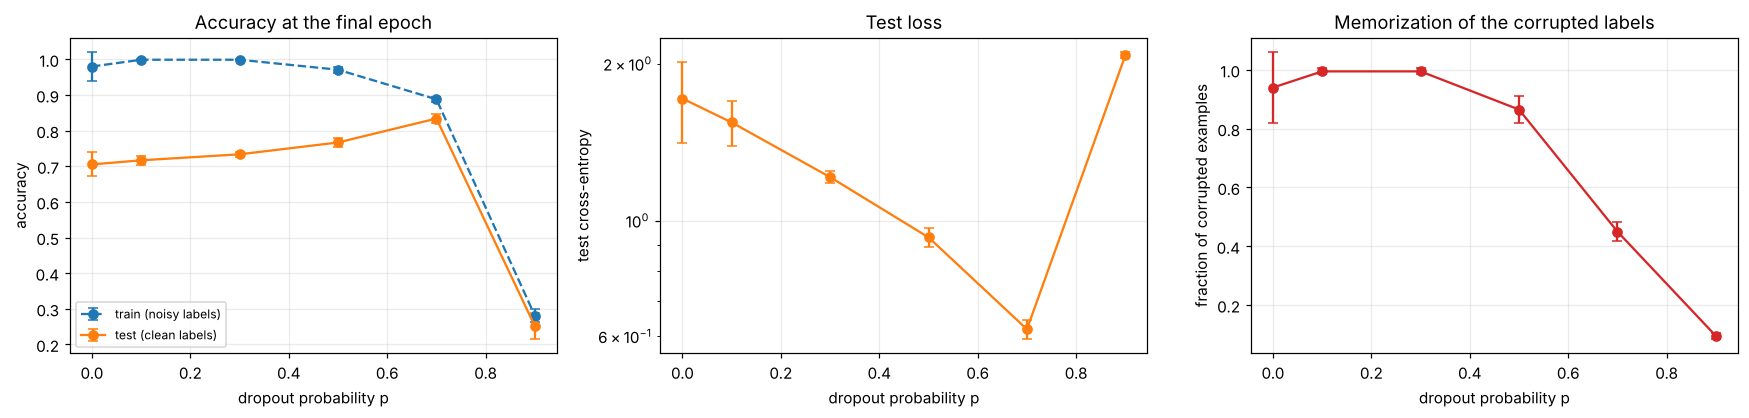

    p | train acc  test acc  test loss  memorized
  0.0 |     0.980     0.705      1.716      0.940
  0.1 |     0.999     0.717      1.544      0.995
  0.3 |     0.999     0.734      1.213      0.995
  0.5 |     0.971     0.767      0.929      0.865
  0.7 |     0.888     0.834      0.619      0.450
  0.9 |     0.281     0.252      2.077      0.095


In [7]:
PS = [0.0, 0.1, 0.3, 0.5, 0.7, 0.9]
t0 = time.time()
for p in PS:
    for s in SEEDS:
        if (p, s) not in runs:
            runs[(p, s)] = run(p, s)
print(f"sweep done in {time.time() - t0:.0f}s")


def final_metrics(p):
    r = []
    for s in SEEDS:
        m, h = runs[(p, s)]
        lt = logits_of(m, Xtr_t)
        ta = (lt.argmax(1) == ytr_t).float().mean().item()
        mem = (lt[CORR].argmax(1) == ytr_t[CORR]).float().mean().item()
        el, ea = nll_acc(logits_of(m, Xte_t), yte_t)
        r.append((ta, ea, el, mem))
    return np.array(r)


sweep = {p: final_metrics(p) for p in PS}
fig, axes = plt.subplots(1, 3, figsize=(16, 3.9))
for col, lab, st in ((0, "train (noisy labels)", "--"), (1, "test (clean labels)", "-")):
    axes[0].errorbar(PS, [sweep[p][:, col].mean() for p in PS], yerr=[sweep[p][:, col].std() for p in PS], marker="o", capsize=3, ls=st, label=lab)
axes[0].set_ylabel("accuracy"); axes[0].set_title("Accuracy at the final epoch")
axes[1].errorbar(PS, [sweep[p][:, 2].mean() for p in PS], yerr=[sweep[p][:, 2].std() for p in PS], marker="o", capsize=3, color="C1")
axes[1].set_yscale("log"); axes[1].set_ylabel("test cross-entropy"); axes[1].set_title("Test loss")
axes[2].errorbar(PS, [sweep[p][:, 3].mean() for p in PS], yerr=[sweep[p][:, 3].std() for p in PS], marker="o", capsize=3, color="C3")
axes[2].set_ylabel("fraction of corrupted examples"); axes[2].set_title("Memorization of the corrupted labels")
for ax in axes:
    ax.set_xlabel("dropout probability p")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'p':>5} | {'train acc':>9} {'test acc':>9} {'test loss':>10} {'memorized':>10}")
for p in PS:
    print(f"{p:>5} | {sweep[p][:, 0].mean():>9.3f} {sweep[p][:, 1].mean():>9.3f} {sweep[p][:, 2].mean():>10.3f} {sweep[p][:, 3].mean():>10.3f}")

**What to notice.** The trade-off is clear. Test accuracy rises with `p` from 0.705 (no dropout) through 0.717, 0.734 and 0.767 to **0.834 at `p = 0.7`**, test loss falls from 1.72 to **0.62**, and the memorization rate falls steadily (0.995 at `p = 0.3`, 0.87 at 0.5, 0.45 at 0.7). At `p = 0.9` the network **underfits**: training accuracy is only 0.28, there is almost nothing left to generalize from, and the test loss shoots back up to 2.1. So there is a sweet spot, and too much regularization is as bad as none.

Three notes. The best value here (0.7) is higher than the textbook 0.5 because 20% label noise calls for strong regularization; the best `p` depends on the problem. We read the best value off the test set purely for illustration, which makes 0.834 slightly optimistic: in practice choose `p` on the validation set and touch the test set once. And the `p = 0` memorization of 0.94 is, again, pulled down by the spiked seed; it is not evidence that small dropout rates memorize more.

## 5. Why does it work? Testing the two explanations

### 5a. Robustness to losing units (the "no co-adaptation" story)

If dropout prevents units from relying on specific partners, the trained network should be **more tolerant of missing units**. We take the trained networks (`p = 0` and `p = 0.5`), and at test time **delete** a random fraction `f` of the hidden units in every layer (no rescaling, as if those units had failed), and measure the test accuracy. 20 random deletions for each of the 5 seeds.

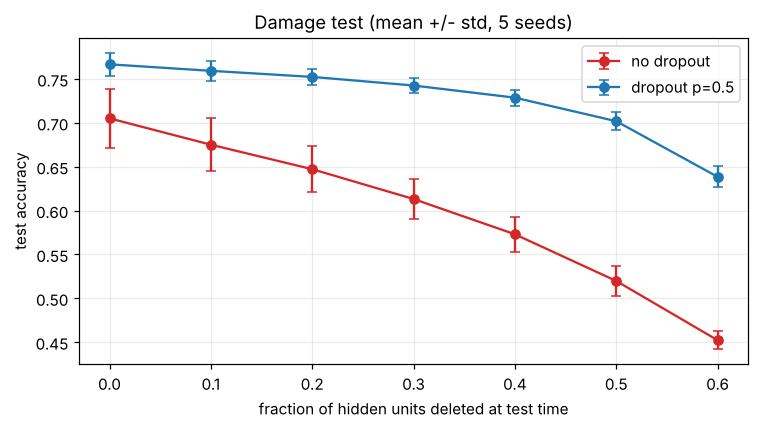

 deleted | no dropout  dropout 0.5
     0.0 |      0.705        0.767
     0.1 |      0.675        0.759
     0.2 |      0.647        0.752
     0.3 |      0.613        0.743
     0.4 |      0.573        0.729
     0.5 |      0.520        0.702
     0.6 |      0.452        0.639


In [8]:
@torch.no_grad()
def ablated_acc(model, f, n_draws=20, seed=0):
    model.eval()
    set_seed(seed)
    return np.mean([(model(Xte_t, ablate=f).argmax(1) == yte_t).float().mean().item() for _ in range(n_draws)])


FS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
abl = {p: np.array([[ablated_acc(runs[(p, s)][0], f, seed=s) for f in FS] for s in SEEDS]) for p in (0.0, 0.5)}
fig, ax = plt.subplots(figsize=(7, 4))
for p, (c, lab) in styles.items():
    ax.errorbar(FS, abl[p].mean(0), yerr=abl[p].std(0), color=c, marker="o", capsize=3, label=lab)
ax.set_xlabel("fraction of hidden units deleted at test time"); ax.set_ylabel("test accuracy")
ax.set_title("Damage test (mean +/- std, 5 seeds)"); ax.legend()
plt.tight_layout(); plt.show()
print(f"{'deleted':>8} | {'no dropout':>10} {'dropout 0.5':>12}")
for i, f in enumerate(FS):
    print(f"{f:>8.1f} | {abl[0.0][:, i].mean():>10.3f} {abl[0.5][:, i].mean():>12.3f}")

**What to notice.** Deleting hidden units hurts the plain network much more. With half the hidden units deleted the plain network loses 18.5 points (0.705 to 0.520), the dropout network only 6.5 (0.767 to 0.702); at 40% deleted it is 0.573 against 0.729. This fits the picture of a network whose features are spread over many units rather than carried by a few fragile combinations.

Be careful about what it proves: the dropout network was *trained* with units randomly missing, so passing this test is partly by construction. It shows redundancy was learned, not by itself that redundancy is the reason for the better generalization.

### 5b. Averaging over masks (the "ensemble" story)

At test time we normally use the full network once (the "weight scaling" approximation of the ensemble average). The ensemble view predicts that **actually averaging the predictions of `K` randomly thinned networks** (Monte Carlo dropout: keep dropout on, run `K` passes, average the softmax outputs) should approach the single deterministic pass as `K` grows, while a **single** random mask should be worse.

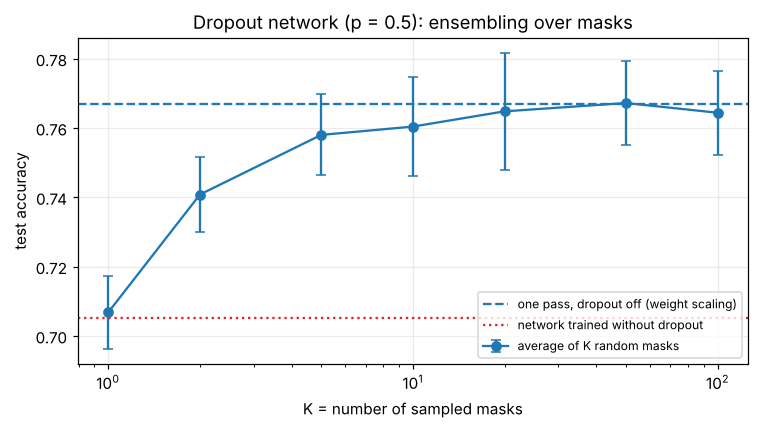

K:            [1, 2, 5, 10, 20, 50, 100]
mean test acc: [0.707 0.741 0.758 0.76  0.765 0.767 0.764]
deterministic pass: 0.767   |   trained without dropout: 0.705


In [9]:
@torch.no_grad()
def mc_dropout_probs(model, X, K, seed=0):
    model.train()                                    # dropout ON at inference
    set_seed(seed)
    probs = torch.stack([F.softmax(model(X), 1) for _ in range(K)]).mean(0)
    model.eval()
    return probs


KS = [1, 2, 5, 10, 20, 50, 100]
mc_acc = np.array([[(mc_dropout_probs(runs[(0.5, s)][0], Xte_t, K, seed=s).argmax(1) == yte_t).float().mean().item()
                    for K in KS] for s in SEEDS])
det_acc = np.array([nll_acc(logits_of(runs[(0.5, s)][0], Xte_t), yte_t)[1] for s in SEEDS])
nodrop_acc = summ[0.0][:, 2]

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(KS, mc_acc.mean(0), yerr=mc_acc.std(0), marker="o", capsize=3, label="average of K random masks")
ax.axhline(det_acc.mean(), color="C0", ls="--", label="one pass, dropout off (weight scaling)")
ax.axhline(nodrop_acc.mean(), color="C3", ls=":", label="network trained without dropout")
ax.set_xscale("log"); ax.set_xlabel("K = number of sampled masks"); ax.set_ylabel("test accuracy")
ax.set_title("Dropout network (p = 0.5): ensembling over masks"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("K:           ", KS)
print("mean test acc:", mc_acc.mean(0).round(3))
print(f"deterministic pass: {det_acc.mean():.3f}   |   trained without dropout: {nodrop_acc.mean():.3f}")

**What to notice.** A **single** random mask (K = 1) gives 0.707, about 6 points below the full network, so one thinned sub-network is clearly worse than the whole. Averaging more masks closes the gap quickly (0.741 at K = 2, 0.758 at K = 5) and by K = 20 to 100 the average sits at 0.764 to 0.767, the same as the **one deterministic pass with dropout off (0.767)**. So the cheap "turn dropout off" inference really is a good approximation to averaging many sub-networks, here with no accuracy to gain from the expensive version. That is consistent with the ensemble explanation. (Monte Carlo dropout is still useful when you want a spread of predictions as an uncertainty estimate.)

### 5c. Calibration: over-confidence

A network that has memorized its training set is typically **over-confident**: it assigns probability close to 1 to its predictions, including the wrong ones. We compare predicted confidence (the maximum softmax probability) with actual accuracy on the test set, pooling the 5 seeds, using the usual reliability diagram and the **expected calibration error** (ECE: the average gap between confidence and accuracy over confidence bins, weighted by how many predictions fall in each bin).

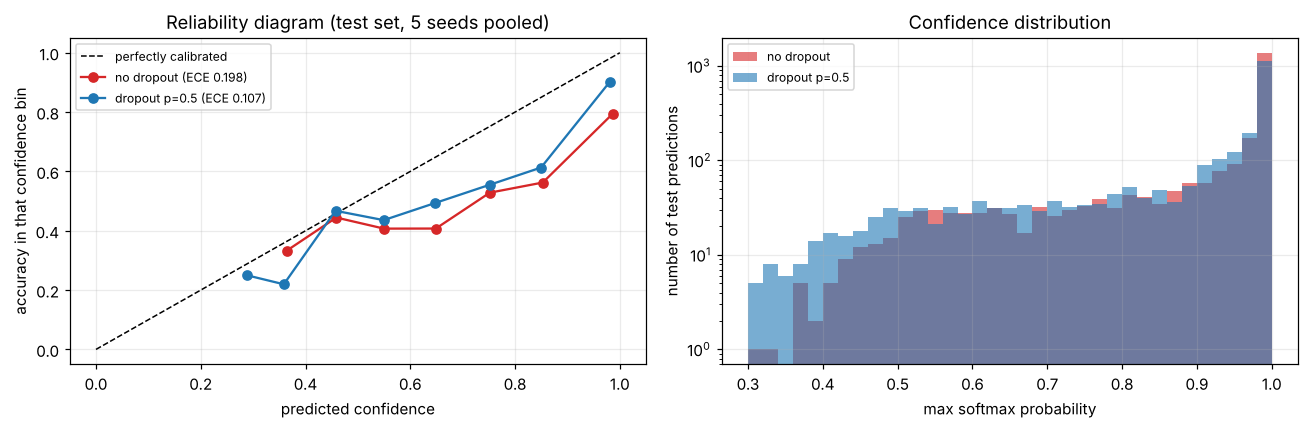

                mean confidence  accuracy     ECE  test NLL
no dropout                0.903     0.705   0.198     1.715
dropout p=0.5             0.873     0.767   0.107     0.929


In [10]:
def pooled_probs(p):
    pr = torch.cat([F.softmax(logits_of(runs[(p, s)][0], Xte_t), 1) for s in SEEDS])
    return pr, yte_t.repeat(len(SEEDS))


def reliability(probs, y, n_bins=10):
    conf, pred = probs.max(1)
    correct = (pred == y).float()
    edges = torch.linspace(0.0, 1.0, n_bins + 1)
    rows, ece = [], 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        sel = (conf > lo) & (conf <= hi)
        if sel.any():
            rows.append((conf[sel].mean().item(), correct[sel].mean().item(), sel.sum().item()))
            ece += sel.float().mean().item() * abs(rows[-1][0] - rows[-1][1])
    return np.array(rows), ece, conf.mean().item(), correct.mean().item()


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="perfectly calibrated")
cal = {}
for p, (c, lab) in styles.items():
    pr, yy = pooled_probs(p)
    rows, ece, mconf, macc = reliability(pr, yy)
    cal[p] = (ece, mconf, macc, F.nll_loss(pr.clamp_min(1e-12).log(), yy).item())
    axes[0].plot(rows[:, 0], rows[:, 1], marker="o", color=c, label=f"{lab} (ECE {ece:.3f})")
    axes[1].hist(pr.max(1).values.numpy(), bins=np.linspace(0.3, 1.0, 36), alpha=0.6, color=c, label=lab)
axes[0].set_xlabel("predicted confidence"); axes[0].set_ylabel("accuracy in that confidence bin"); axes[0].set_title("Reliability diagram (test set, 5 seeds pooled)"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("max softmax probability"); axes[1].set_ylabel("number of test predictions"); axes[1].set_title("Confidence distribution"); axes[1].set_yscale("log"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"{'':<14} {'mean confidence':>16} {'accuracy':>9} {'ECE':>7} {'test NLL':>9}")
for p, (c, lab) in styles.items():
    e, mc, ac, nl = cal[p]
    print(f"{lab:<14} {mc:>16.3f} {ac:>9.3f} {e:>7.3f} {nl:>9.3f}")

**What to notice.** Both networks are over-confident (mean confidence 0.90 and 0.87 against accuracies of 0.71 and 0.77), and both pile most predictions in the top bin. Dropout roughly **halves the calibration error (ECE 0.107 against 0.198)** and the test negative log-likelihood falls from 1.72 to 0.93, but it does not fix over-confidence: the dropout network is still about 0.1 too confident on average, and its reliability curve lies below the diagonal. Dropout's calibration benefit is real but partial; temperature scaling or similar post-hoc calibration remains useful.

### 5d. The train/eval trap

Dropout behaves differently in `train()` and `eval()` mode, so forgetting `model.eval()` at inference silently adds random noise to every prediction. We run the dropout-trained network 200 times on the test set in each mode and compare how much the predictions fluctuate:

In [11]:
m = runs[(0.5, 0)][0]
with torch.no_grad():
    m.train(); preds_train = torch.stack([m(Xte_t).argmax(1) for _ in range(200)])
    m.eval();  pred_eval = m(Xte_t).argmax(1)
acc_train_mode = (preds_train == yte_t).float().mean(1)                    # accuracy of each of the 200 noisy passes
changed = (preds_train != pred_eval).float().mean()                         # how often a prediction differs from the eval prediction
print(f"eval mode : accuracy {(pred_eval == yte_t).float().mean():.3f} on every call (deterministic)")
print(f"train mode: accuracy {acc_train_mode.mean():.3f} on average, between {acc_train_mode.min():.3f} and {acc_train_mode.max():.3f} across 200 calls")
print(f"            {changed:.1%} of individual predictions differ from the eval-mode prediction")
print(f"            test examples whose predicted class is not the same in all 200 train-mode calls: {int((preds_train != preds_train[0]).any(0).sum())} of {len(yte_t)}")

eval mode : accuracy 0.780 on every call (deterministic)
train mode: accuracy 0.714 on average, between 0.678 and 0.752 across 200 calls
            17.6% of individual predictions differ from the eval-mode prediction
            test examples whose predicted class is not the same in all 200 train-mode calls: 437 of 500


**What to notice.** In `eval()` mode the network gives the same answer on every call (accuracy 0.780 for this seed). Left in `train()` mode, the accuracy of each pass varies between 0.68 and 0.75 (0.714 on average, about 7 points lower), 17.6% of individual predictions differ from the `eval()` prediction, and 437 of the 500 test examples get at least one different predicted class over the 200 calls. Always call `model.eval()` for inference (and `model.train()` again before training).

## 6. When does dropout help less?

Regularization is a remedy for **too much capacity relative to what the data can support**. We test two predictions: the benefit should **grow with the amount of label noise** (more to memorize) and **shrink as the training set grows** (less room to overfit). Each setting is 100 epochs and 3 seeds, for `p = 0` and `p = 0.5`.

### 6a. Label noise, at a fixed 200 training images

done in 35s


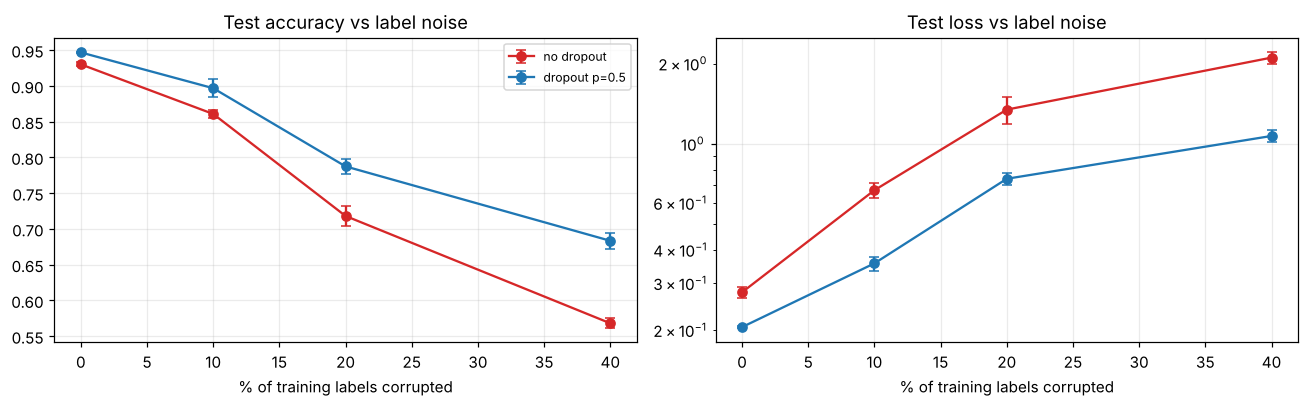

 noise | test acc: none  dropout | test loss: none  dropout
    0% |          0.930    0.947 |           0.278    0.206
   10% |          0.861    0.897 |           0.671    0.356
   20% |          0.718    0.787 |           1.345    0.740
   40% |          0.568    0.683 |           2.108    1.071


In [12]:
SEEDS3 = range(3)


def one(p, n, noise, seed):
    X, y, _, cor = make_train(n, noise)
    m = new_model(p, seed=seed)
    fit(m, X, y, epochs=100, seed=seed, corrupted=cor)
    el, ea = nll_acc(logits_of(m, Xte_t), yte_t)
    return ea, el


t0 = time.time()
NOISES = [0.0, 0.1, 0.2, 0.4]
noise_res = {(nz, p): np.array([one(p, 200, nz, s) for s in SEEDS3]) for nz in NOISES for p in (0.0, 0.5)}
print(f"done in {time.time() - t0:.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for p, (c, lab) in styles.items():
    for j, (col, ttl) in enumerate(((0, "Test accuracy"), (1, "Test loss"))):
        axes[j].errorbar([100 * z for z in NOISES], [noise_res[(z, p)][:, col].mean() for z in NOISES],
                         yerr=[noise_res[(z, p)][:, col].std() for z in NOISES], marker="o", capsize=3, color=c, label=lab)
        axes[j].set_title(ttl + " vs label noise"); axes[j].set_xlabel("% of training labels corrupted")
axes[1].set_yscale("log"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"{'noise':>6} | {'test acc: none':>14} {'dropout':>8} | {'test loss: none':>15} {'dropout':>8}")
for z in NOISES:
    print(f"{z:>6.0%} | {noise_res[(z, 0.0)][:, 0].mean():>14.3f} {noise_res[(z, 0.5)][:, 0].mean():>8.3f} | {noise_res[(z, 0.0)][:, 1].mean():>15.3f} {noise_res[(z, 0.5)][:, 1].mean():>8.3f}")

**What to notice.** The more label noise, the more dropout helps. The accuracy gain is +1.7 points with clean labels, +3.6 at 10% noise, +6.9 at 20% and +11.5 at 40%, and the test loss is cut by roughly a quarter with clean labels and by about half at 10% to 40%. Both networks degrade with noise, but the plain one degrades faster because it fits the corrupted labels. (The 20% row is a 3-seed, 100-epoch run, so it differs a little from the 5-seed, 150-epoch numbers in section 3: 0.718 against 0.787 here, 0.705 against 0.767 there.)

### 6b. Training-set size, with clean labels (50 to 997 images)

done in 85s


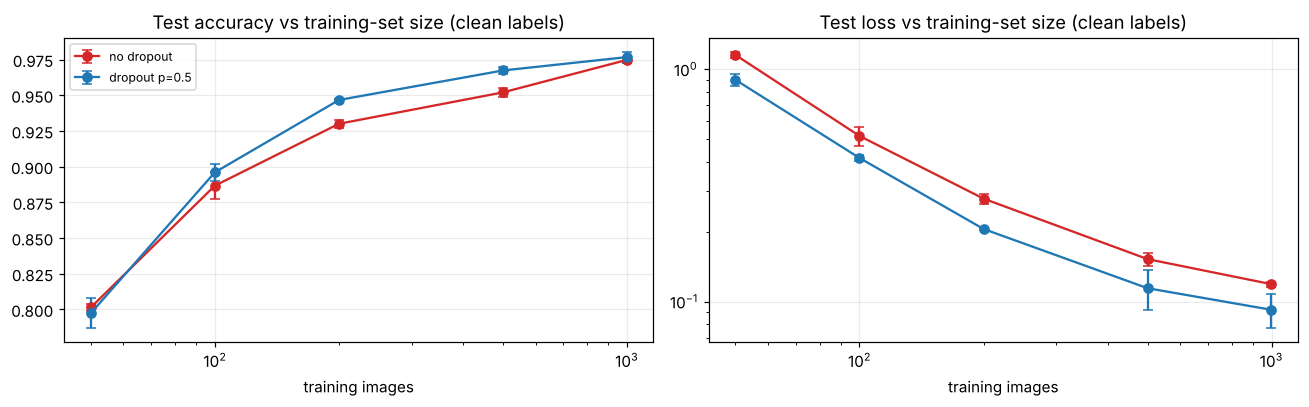

    n | test acc: none  dropout | test loss: none  dropout
   50 |          0.801    0.797 |           1.154    0.902
  100 |          0.887    0.896 |           0.517    0.415
  200 |          0.930    0.947 |           0.278    0.206
  500 |          0.952    0.967 |           0.152    0.114
  997 |          0.975    0.977 |           0.119    0.092


In [13]:
SIZES = [50, 100, 200, 500, 997]
t0 = time.time()
size_res = {(n, p): np.array([one(p, n, 0.0, s) for s in SEEDS3]) for n in SIZES for p in (0.0, 0.5)}
print(f"done in {time.time() - t0:.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for p, (c, lab) in styles.items():
    for j, (col, ttl) in enumerate(((0, "Test accuracy"), (1, "Test loss"))):
        axes[j].errorbar(SIZES, [size_res[(n, p)][:, col].mean() for n in SIZES], yerr=[size_res[(n, p)][:, col].std() for n in SIZES],
                         marker="o", capsize=3, color=c, label=lab)
        axes[j].set_title(ttl + " vs training-set size (clean labels)"); axes[j].set_xlabel("training images"); axes[j].set_xscale("log")
axes[1].set_yscale("log"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"{'n':>5} | {'test acc: none':>14} {'dropout':>8} | {'test loss: none':>15} {'dropout':>8}")
for n in SIZES:
    print(f"{n:>5} | {size_res[(n, 0.0)][:, 0].mean():>14.3f} {size_res[(n, 0.5)][:, 0].mean():>8.3f} | {size_res[(n, 0.0)][:, 1].mean():>15.3f} {size_res[(n, 0.5)][:, 1].mean():>8.3f}")

**What to notice.** With **clean labels** the picture is much more modest, and honest reporting matters here. The test-loss improvement shrinks steadily as data grows (about 0.25, 0.10, 0.07, 0.04 and 0.03 for 50, 100, 200, 500 and 997 images), as predicted. The accuracy gains are small: roughly 0 at 50 images (0.801 against 0.797, no improvement), +0.9 at 100, +1.7 at 200, +1.5 at 500 and +0.2 at 997 points, which with only 3 seeds is close to noise at the extremes. So "less data, more benefit" holds for the loss but not cleanly for accuracy: with very few images, dropout's noise also makes it harder to learn the real pattern.

The overall lesson of the notebook: dropout is a good fix for **overfitting that is actually hurting** (noisy labels, a model much larger than the data can support). On a clean, easy problem it gives a modest gain in loss and calibration and little in accuracy.

## 7. Summary

**What dropout does.** In training, every hidden unit is dropped with probability `p` and the survivors are scaled by `1/(1-p)`; at inference nothing is dropped and nothing needs to be rescaled.

**What this notebook found**

1. **With and without (section 3).** On 200 images with 20% corrupted labels, the plain network memorized the wrong labels (100% by epoch 100) and its validation accuracy fell from 0.82 to 0.68. The dropout network memorized much more slowly and ended better: test accuracy 0.767 against 0.705 and test loss 0.93 against 1.72, in all 5 seeds.
2. **There is a sweet spot (section 4).** Test accuracy kept improving up to `p = 0.7` (0.834) and collapsed at 0.9 (underfitting).
3. **Both stories got some support (section 5).** The dropout network tolerates deleted units much better (5a), and the ordinary dropout-off pass matches the average of 20 or more sampled sub-networks (5b). Calibration roughly doubled in quality (ECE 0.107 against 0.198) but over-confidence did not disappear (5c).
4. **The size of the benefit depends on the problem (section 6).** Large with noisy labels (+11.5 accuracy points at 40% noise), small with clean labels (at most about 2 points, mostly visible in the loss).
5. **It is not magic.** Dropout delays memorization rather than preventing it; with early stopping most of the end-of-training advantage disappears (best validation loss 0.67 against 0.60), and it slows down early learning.

**Practical notes**

- Typical rates: 0.1 to 0.5 on hidden layers of fully connected networks, often 0.1 or lower in convolutional and transformer layers. Choose `p` on a validation set; the best value grows with how much overfitting you have to fight.
- Always call `model.eval()` for inference (5d). Dropout needs more epochs to converge, so do not judge it on the first few.
- Dropout is not a substitute for clean data, weight decay, data augmentation or early stopping; they combine well.
- Dropout and BatchNorm can interact badly, because dropout changes the variance of activations between training and inference. If you use both, test the combination, for example with dropout after the normalization or at a low rate.
- Monte Carlo dropout (keep it on at test time and average `K` passes) gives a cheap spread of predictions for uncertainty estimation.

**Try it yourself**

1. Add early stopping (keep the epoch with the best validation loss) to both networks and recompute the section 3 table. How much of the gap is left?
2. Replace dropout with weight decay (`torch.optim.AdamW`, e.g. `weight_decay=1e-2`). Does it limit memorization of the corrupted labels as well?
3. Apply dropout only to the last hidden layer, then only to the first.
4. Add input dropout (`p = 0.1` to `0.2` on the pixels) on top of hidden-layer dropout.
5. Pick `p` using the validation set only and report the test accuracy once.
6. Widen the network (`width = 1024`) or deepen it. Does the benefit of dropout grow with capacity?